## Usco Lightcurve Plot

In [1]:
#Get the imports
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models

In [2]:
#The data

In [2]:
data = (

[59755.22,	2.6,	0.005,	0.036],
[59755.22,	3.4,	0.0002,	0.022],
[59755.22,	5.1,	0.013,	0.023],
[59755.22,	7.0,	0.061,	0.019],
[59755.22,	13.7,	0.211,	0.027],
[59755.22,	16.5,	0.216,	0.032],
[59755.22,	31.1,	0.424,	0.081],
[59755.22,	34.9,	0.452,	0.099],
[59769.25,	2.6,	0.019,	0.032],
[59769.25,	3.4,	0.013,	0.028],
[59769.25,	5.1,	0.065,	0.031],
[59769.25,	7.0,	0.115,	0.029],
[59769.25,	13.7,	0.125,	0.031],
[59769.25,	16.5,	0.169,	0.029],
[59769.25,	31.1,	0.010,	0.099],
[59769.25,	34.9,	0.193,	0.126],
[59776.14,	2.6,	0.002,	0.009],
[59776.14,	3.4,	0.010,	0.015],
[59776.14,	5.1,	0.017,	0.010],
[59776.14,	7.0,	0.057,	0.026],
[59776.14,	13.7,	0.105,	0.012],
[59776.14,	16.5,	0.108,	0.013],
[59776.14,	31.1,	0.185,	0.044],
[59776.14,	34.9,	0.152,	0.052],
[59796.03,	2.6,	0,	0.038],
[59796.03,	3.4,	0.026,	0.025],
[59796.03,	5.1,	0.024,	0.022],
[59796.03,	7.0,	0.030,	0.020],
[59796.03,	13.7,	0.048,	0.025],
[59796.03,	16.5,	0.042,	0.029],
[59796.03,	31.1,	0.103,	0.072],
[59796.03,	34.9,	0.009,	0.083],
[59815.03,	2.6,	0.020,	0.057],
[59815.03,	3.4,	0.018,	0.027],
[59815.03,	5.1,	0.025,	0.024],
[59815.03,	7.0,	0.020,	0.023],
[59815.03,	13.7,	0.014,	0.022],
[59815.03,	16.5,	0.023,	0.027],
[59815.03,	31.1,	0.035,	0.065],
[59815.03,	34.9,	0.026,	0.070]

)

df =  pd.DataFrame(data, columns = ["MJD",	"Frequency(GHz)",	"Fluxdensity(mJy)",	"error(mJy)"])

In [3]:
f2_6 = (
 [59755.22,	2.6,	0.005,	0.036],
    [59769.25,	2.6,	0.019,	0.032],
    [59776.14,	2.6,	0.002,	0.009],
    [59796.03,	2.6,	0,	0.038],
    [59815.03,	2.6,	0.020,	0.057],
)

f3_4 = (
[59755.22,	3.4,	0.0002,	0.022],
    [59769.25,	3.4,	0.013,	0.028],
    [59776.14,	3.4,	0.010,	0.015],
    [59796.03,	3.4,	0.026,	0.025],
    [59815.03,	3.4,	0.018,	0.027],
)

f5_1 = (
[59755.22,	5.1,	0.013,	0.023],
    [59769.25,	5.1,	0.065,	0.031],
    [59776.14,	5.1,	0.017,	0.010],
    [59796.03,	5.1,	0.024,	0.022],
    [59815.03,	5.1,	0.025,	0.024],
)

f7 = (
[59755.22,	7.0,	0.061,	0.019],
    [59769.25,	7.0,	0.115,	0.029],
    [59776.14,	7.0,	0.057,	0.026],
    [59796.03,	7.0,	0.030,	0.020],
    [59815.03,	7.0,	0.020,	0.023],
)

f13_7 = (
[59755.22,	13.7,	0.211,	0.027],
    [59769.25,	13.7,	0.125,	0.031],
    [59776.14,	13.7,	0.105,	0.012],
    [59796.03,	13.7,	0.048,	0.025],
    [59815.03,	13.7,	0.014,	0.022],
)

f16_5 = (
[59755.22,	16.5,	0.216,	0.032],
    [59769.25,	16.5,	0.169,	0.029],
    [59776.14,	16.5,	0.108,	0.013],
    [59796.03,	16.5,	0.042,	0.029],
    [59815.03,	16.5,	0.023,	0.027],
)

f31_1 = (
[59755.22,	31.1,	0.424,	0.081],
    [59769.25,	31.1,	0.010,	0.099],
    [59776.14,	31.1,	0.185,	0.044],
    [59796.03,	31.1,	0.103,	0.072],
    [59815.03,	31.1,	0.035,	0.065],
)

f34_9 = (
[59755.22,	34.9,	0.452,	0.099],
    [59769.25,	34.9,	0.193,	0.126],
    [59776.14,	34.9,	0.152,	0.052],
    [59796.03,	34.9,	0.009,	0.083],
    [59815.03,	34.9,	0.026,	0.070]
)



In [13]:

df2_6 =  pd.DataFrame(f2_6, columns = ["MJD",	"Frequency(GHz)",	"Fluxdensity(mJy)",	"error(mJy)"])

df3_4 =  pd.DataFrame(f3_4, columns = ["MJD",	"Frequency(GHz)",	"Fluxdensity(mJy)",	"error(mJy)"])

df5_1 =  pd.DataFrame(f5_1, columns = ["MJD",	"Frequency(GHz)",	"Fluxdensity(mJy)",	"error(mJy)"])

df7 =  pd.DataFrame(f7, columns = ["MJD",	"Frequency(GHz)",	"Fluxdensity(mJy)",	"error(mJy)"])

df13_7 =  pd.DataFrame(f13_7, columns = ["MJD",	"Frequency(GHz)",	"Fluxdensity(mJy)",	"error(mJy)"])

df16_5 =  pd.DataFrame(f16_5, columns = ["MJD",	"Frequency(GHz)",	"Fluxdensity(mJy)",	"error(mJy)"])

df31_1 =  pd.DataFrame(f31_1, columns = ["MJD",	"Frequency(GHz)",	"Fluxdensity(mJy)",	"error(mJy)"])

df34_9 =  pd.DataFrame(f34_9, columns = ["MJD",	"Frequency(GHz)",	"Fluxdensity(mJy)",	"error(mJy)"])

### Eruption on MJD 59736.72 (from Moriyama M., 2022, vsnet-alert 26798)

# Now for the optical data 

In [7]:
#optical data input

Usco_opt_unflitered = pd.read_csv('aavsodata_69d3e5d86b382.txt', header = 0)

#now to get only the vband

column_name = 'Band'
key = 'V'

Usco_opt_kinda = Usco_opt_unflitered[Usco_opt_unflitered[column_name].str.contains(key, na=False)]

Usco_opt = Usco_opt_kinda[~Usco_opt_kinda[column_name].str.contains('Vis.|CV', na=False)]



In [8]:
#MJD/t0 = 59736.72
#JD = 2459736.72

opticaldays = ((Usco_opt['JD'].astype(float)) - 2459736.72)
vmag = Usco_opt['Magnitude'].astype(float)
error_vmag = Usco_opt['Uncertainty'].astype(float)

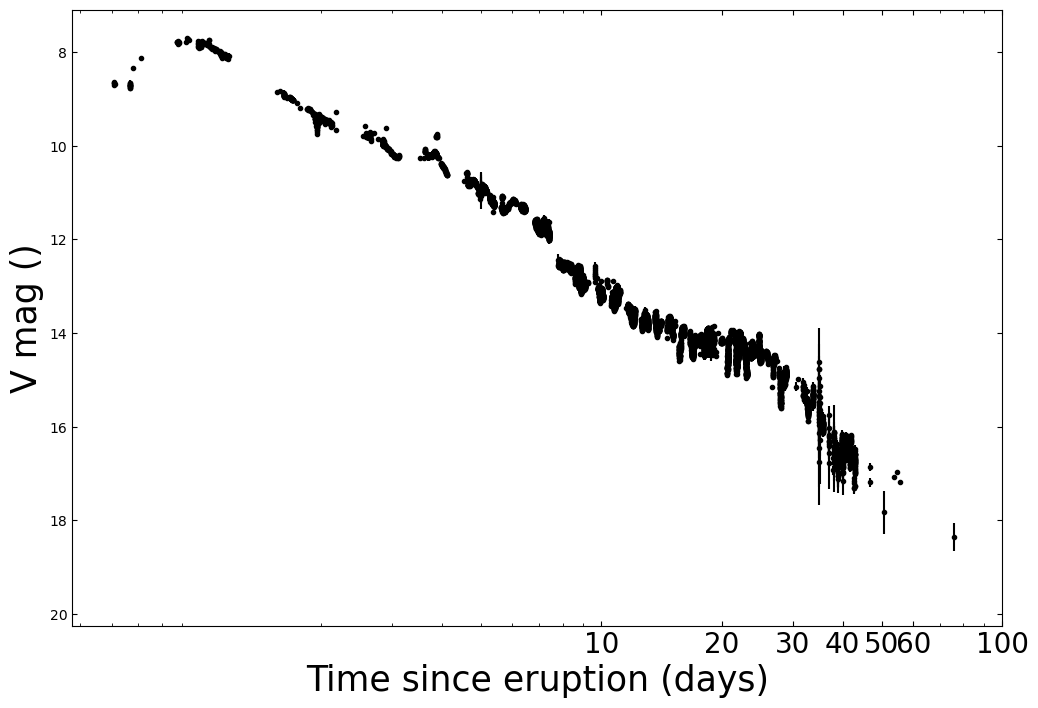

In [9]:
fig, ax = plt.subplots()

fig.set_size_inches(12,8)

ax.errorbar( opticaldays, vmag, yerr=error_vmag, fmt='.', color='black')

ax.set_xscale('log')
ax.set_xticks([10,20,30,40,50,60,100], labels = ['10','20', '30', '40','50', '60','100'], fontsize = 20)
#ax.set_yscale('log')
#ax.set_yticks([0.1,1], labels = [r], fontsize = 20)
ax.invert_yaxis()
ax.set_xlabel("Time since eruption (days)", fontsize = 25)
ax.set_ylabel("V mag ()", fontsize = 25)

ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax.set_title("")
plt.show();

# Now both together

In [14]:
#detection lists

mask0 =  df2_6['Fluxdensity(mJy)'] > 3 * np.sqrt(df2_6["error(mJy)"]**2 + (df2_6["Fluxdensity(mJy)"]*0.05)**2) #don't show the non-detections
days2_6d = df2_6['MJD'][mask0] - 59736.72
flux2_6d = df2_6["Fluxdensity(mJy)"][mask0]
flux_err2_6d = np.sqrt(df2_6["error(mJy)"][mask0]**2 + (df2_6["Fluxdensity(mJy)"][mask0]*0.05)**2)

mask1 =  df3_4['Fluxdensity(mJy)'] > 3 * np.sqrt(df3_4["error(mJy)"]**2 + (df3_4["Fluxdensity(mJy)"]*0.05)**2) #don't show the non-detections
days3_4d = df3_4['MJD'][mask1] - 59736.72
flux3_4d = df3_4["Fluxdensity(mJy)"][mask1]
flux_err3_4d = np.sqrt(df3_4["error(mJy)"][mask0]**2 + (df3_4["Fluxdensity(mJy)"][mask1]*0.05)**2)

mask2 =  df5_1['Fluxdensity(mJy)'] > 3 * np.sqrt(df5_1["error(mJy)"]**2 + (df5_1["Fluxdensity(mJy)"]*0.05)**2) #don't show the non-detections
days5_1d = df5_1['MJD'][mask2] - 59736.72
flux5_1d = df5_1["Fluxdensity(mJy)"][mask2]
flux_err5_1d = np.sqrt(df5_1["error(mJy)"][mask2]**2 + (df5_1["Fluxdensity(mJy)"][mask2]*0.05)**2)

mask3 =  df7['Fluxdensity(mJy)'] > 3 * np.sqrt(df7["error(mJy)"]**2 + (df7["Fluxdensity(mJy)"]*0.05)**2) #don't show the non-detections
days7d = df7['MJD'][mask3] - 59736.72
flux7d = df7["Fluxdensity(mJy)"][mask3]
flux_err7d = np.sqrt(df7["error(mJy)"][mask3]**2 + (df7["Fluxdensity(mJy)"][mask3]*0.05)**2)

mask4 =  df13_7['Fluxdensity(mJy)'] > 3 * np.sqrt(df13_7["error(mJy)"]**2 + (df13_7["Fluxdensity(mJy)"]*0.1)**2) #don't show the non-detections
days13_7d = df13_7['MJD'][mask4] - 59736.72
flux13_7d = df13_7["Fluxdensity(mJy)"][mask4]
flux_err13_7d = np.sqrt(df13_7["error(mJy)"][mask4]**2 + (df13_7["Fluxdensity(mJy)"][mask4]*0.1)**2)

mask5 =  df16_5['Fluxdensity(mJy)'] > 3 * np.sqrt(df16_5["error(mJy)"]**2 + (df16_5["Fluxdensity(mJy)"]*0.1)**2) #don't show the non-detections
days16_5d = df16_5['MJD'][mask5] - 59736.72
flux16_5d = df16_5["Fluxdensity(mJy)"][mask5]
flux_err16_5d = np.sqrt(df16_5["error(mJy)"][mask5]**2 + (df16_5["Fluxdensity(mJy)"][mask5]*0.1)**2)


mask6 =  df31_1['Fluxdensity(mJy)'] > 3 * np.sqrt(df31_1["error(mJy)"]**2 + (df31_1["Fluxdensity(mJy)"]*0.1)**2) #don't show the non-detections
days31_1d = df31_1['MJD'][mask6] - 59736.72
flux31_1d = df31_1["Fluxdensity(mJy)"][mask6]
flux_err31_1d = np.sqrt(df31_1["error(mJy)"][mask6]**2 + (df31_1["Fluxdensity(mJy)"][mask6]*0.1)**2)

mask7 =  df34_9['Fluxdensity(mJy)'] > 3 * np.sqrt(df34_9["error(mJy)"]**2 + (df34_9["Fluxdensity(mJy)"]*0.1)**2) #don't show the non-detections
days34_9d = df34_9['MJD'][mask7] - 59736.72
flux34_9d = df34_9["Fluxdensity(mJy)"][mask7]
flux_err34_9d = np.sqrt(df34_9["error(mJy)"][mask7]**2 + (df34_9["Fluxdensity(mJy)"][mask7]*0.1)**2)

In [15]:
# non detection lists

mask0 =  df2_6['Fluxdensity(mJy)'] < 3 * df2_6["error(mJy)"]
days2_6nd = df2_6['MJD'][mask0] - 59736.72
flux2_6nd = (df2_6['Fluxdensity(mJy)'][mask0] + 3*df2_6['error(mJy)'][mask0])

mask1 =  df3_4['Fluxdensity(mJy)'] < 3 * df3_4["error(mJy)"]
days3_4nd = df3_4['MJD'][mask1] - 59736.72
flux3_4nd = (df3_4['Fluxdensity(mJy)'][mask1] + 3*df3_4['error(mJy)'][mask1])

mask2 =  df5_1['Fluxdensity(mJy)'] < 3 * df5_1["error(mJy)"] 
days5_1nd = df5_1['MJD'][mask2] - 59736.72
flux5_1nd = (df5_1['Fluxdensity(mJy)'][mask2] + 3*df5_1['error(mJy)'][mask2])

mask3 =  df7['Fluxdensity(mJy)'] < 3 * df7["error(mJy)"]
days7nd = df7['MJD'][mask3] - 59736.72
flux7nd =  (df7['Fluxdensity(mJy)'][mask3] + 3*df7['error(mJy)'][mask3])

mask4 =  df13_7['Fluxdensity(mJy)'] < 3 * df13_7["error(mJy)"]
days13_7nd = df13_7['MJD'][mask4] - 59736.72
flux13_7nd = (df13_7['Fluxdensity(mJy)'][mask4] + 3*df13_7['error(mJy)'][mask4])

mask5 =  df16_5['Fluxdensity(mJy)'] < 3 * df16_5["error(mJy)"]
days16_5nd = df16_5['MJD'][mask5] - 59736.72
flux16_5nd = (df16_5['Fluxdensity(mJy)'][mask5] + 3*df16_5['error(mJy)'][mask5])


mask6 =  df31_1['Fluxdensity(mJy)'] < 3 * df31_1["error(mJy)"]
days31_1nd = df31_1['MJD'][mask6] - 59736.72
flux31_1nd = (df31_1['Fluxdensity(mJy)'][mask6] + 3*df31_1['error(mJy)'][mask6])

mask7 =  df34_9['Fluxdensity(mJy)'] < 3 * df34_9["error(mJy)"]
days34_9nd = df34_9['MJD'][mask7] - 59736.72
flux34_9nd = (df34_9['Fluxdensity(mJy)'][mask7] + 3*df34_9['error(mJy)'][mask7])



In [12]:
alpha = [1.41,0.38,0.44]

alpha_err = [0.17,0.75,0.27]

alpha_day = [18.5,32.5,39.4]

In [13]:
#day 18.5 
freq_1 = [7,13.7,16.5,31.1,34.9]
flux_1 = [0.061,0.211,0.216,0.424,0.452]
err_1 = [0.019243, 0.034267,0.038608,0.091426,0.10883]

#day 32.5 
freq_2 = [7,13.7,16.5]
flux_2 = [0.115,0.125,0.169]
err_2 = [0.029565, 0.033425, 0.033565]

#day 39.4 
freq_3 = [13.7,16.5, 31.1]
flux_3 = [0.105,0.108,0.185]
err_3 = [0.015945, 0.016901,0.047731]

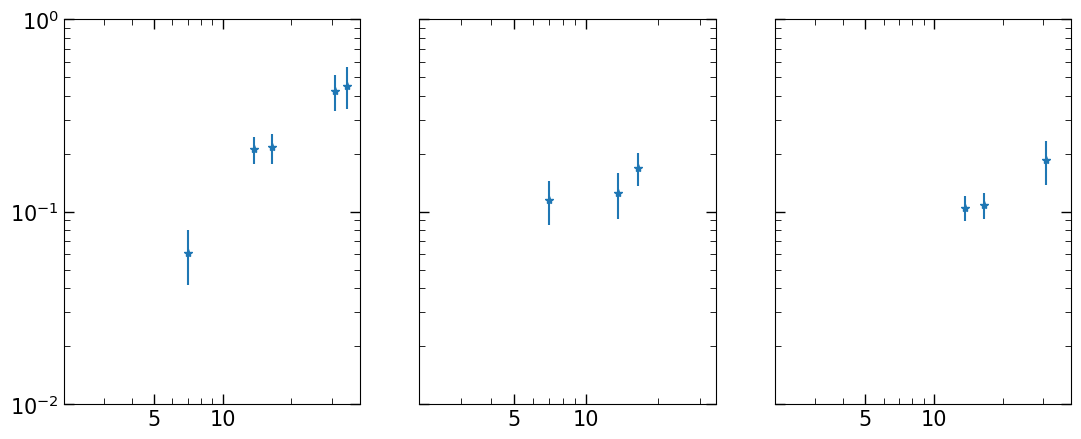

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(13, 5), sharey=True, sharex = False)#, constrained_layout=True)



axs[0].errorbar(freq_1, flux_1, yerr=err_1, fmt = '*')
axs[0].set_xscale('log')
axs[0].set_yscale('log')


axs[0].set_xticks([5,10], labels = ['5','10'], fontsize=15)
axs[0].set_xlim([2,40])

axs[0].set_yticks([0.05, 0.10, 0.50], labels = [r'$0.05$',r'$0.1$',r'$0.5$'], fontsize=15)

axs[0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[0].tick_params(which='major', length=7, direction = 'in', width =1, left=True, labelleft=True, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
axs[0].set_ylim([0.01,1])



axs[1].errorbar(freq_2, flux_2, yerr=err_2, fmt = '*')
axs[1].set_xscale('log')
axs[1].set_yscale('log')
axs[1].set_xticks([5,10], labels = ['5','10'],fontsize=15)
axs[1].set_xlim([2,35])
axs[1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)



axs[2].errorbar(freq_3, flux_3, yerr=err_3,fmt = '*')
axs[2].set_xscale('log')
axs[2].set_yscale('log')

axs[2].set_xticks([5,10], labels = ['5','10'],fontsize=15)
axs[2].set_xlim([2,40])

axs[2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

plt.show()

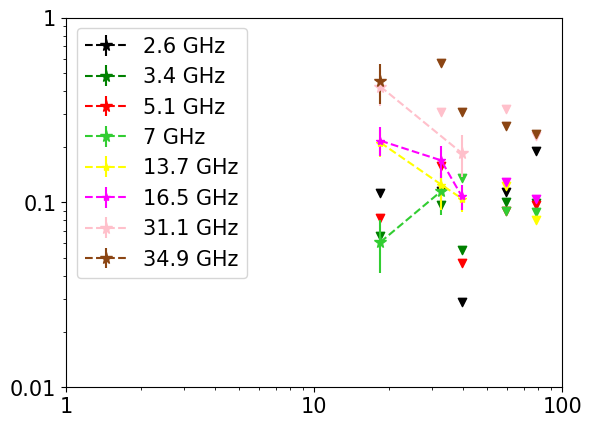

In [16]:
#now the radio
plt.xscale('log')
plt.yscale('log')



plt.errorbar(days2_6d, flux2_6d, yerr=flux_err2_6d, linestyle ='--', color = 'black', fmt = '*' , markersize = 8.5, label='2.6 GHz')
plt.errorbar(days3_4d, flux3_4d, yerr=flux_err3_4d, linestyle ='--', color = 'green', fmt = '*' , markersize = 8.5, label='3.4 GHz')

plt.errorbar(days5_1d, flux5_1d, yerr=flux_err5_1d, linestyle ='--', color = 'red',fmt = '*', markersize = 8.5, label='5.1 GHz')
plt.errorbar(days7d, flux7d, yerr=flux_err7d, linestyle ='--', color = 'limegreen',fmt = '*', markersize = 8.5, label='7 GHz')

plt.errorbar(days13_7d, flux13_7d, yerr=flux_err13_7d, linestyle ='--', color = 'yellow',fmt = '*' , label='13.7 GHz')
plt.errorbar(days16_5d, flux16_5d, yerr=flux_err16_5d, linestyle ='--', color = 'fuchsia',fmt = '*' , label='16.5 GHz')

plt.errorbar(days31_1d, flux31_1d, yerr=flux_err31_1d, linestyle ='--', color = 'pink',fmt = '*' , markersize = 8.5, label='31.1 GHz')
plt.errorbar(days34_9d, flux34_9d, yerr=flux_err34_9d, linestyle ='--', color = 'saddlebrown',fmt = '*' , markersize = 8.5, label='34.9 GHz')


plt.scatter(days2_6nd, flux2_6nd , marker = 'v', color='black')
plt.scatter(days3_4nd, flux3_4nd , marker = 'v',color='green')
plt.scatter(days5_1nd, flux5_1nd , marker = 'v',color='red')
plt.scatter(days7nd, flux7nd , marker = 'v',color='limegreen')
plt.scatter(days13_7nd, flux13_7nd , marker = 'v', color='yellow')
plt.scatter(days16_5nd, flux16_5nd , marker = 'v', color='fuchsia')

plt.scatter(days31_1nd, flux31_1nd , marker = 'v', color='pink')
plt.scatter(days34_9nd, flux34_9nd , marker = 'v', color='saddlebrown')

plt.xticks([1,10,100], labels=['1','10','100'], fontsize=15)
plt.yticks([0.01,0.1,1], labels=['0.01','0.1','1'], fontsize=15)

plt.legend(fontsize=15)
plt.show()

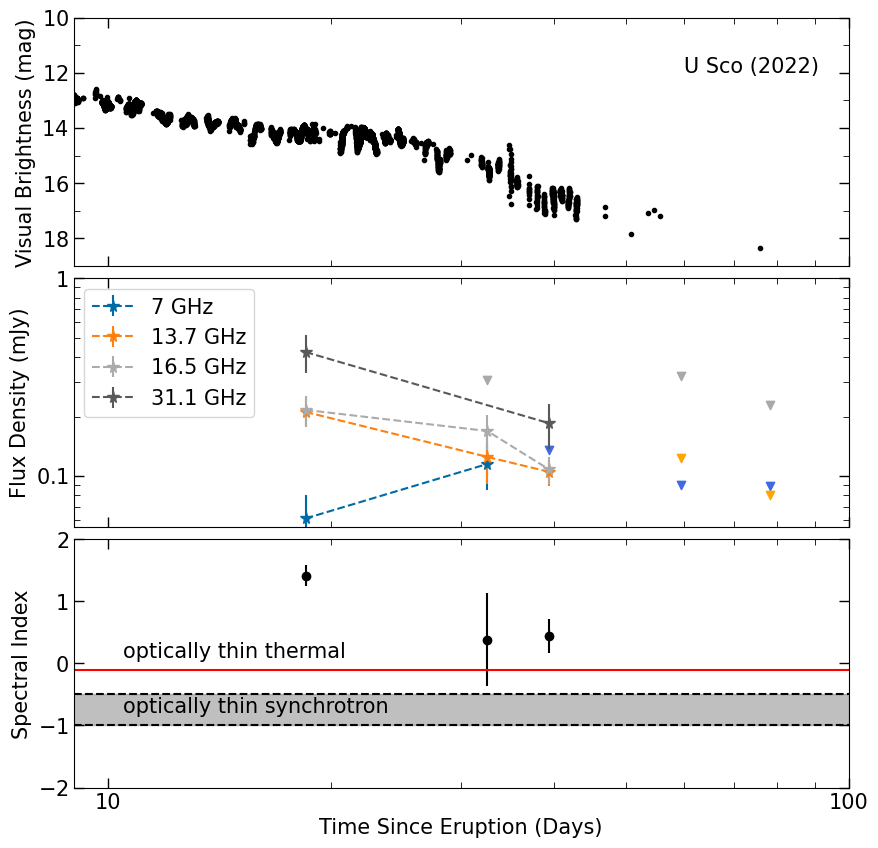

In [19]:
##### 
plt.style.use('tableau-colorblind10')
#plt.style.use('dark_background')

from matplotlib.ticker import AutoMinorLocator

fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharey=False, sharex = True)#, constrained_layout=True)


#first the visual
axs[0].set_xscale('log')

axs[0].scatter(opticaldays, vmag, marker = '.', color = 'black')
axs[0].annotate('U Sco (2022)',(60,12), fontsize=15)

axs[0].set_ylabel('Visual Brightness (mag)',fontsize =15)


axs[0].invert_yaxis()
axs[0].set_yticks([10,12,14,16,18], labels = [r'$10$',r'$12$', r'$14$',r'$16$', r'$18$'], fontsize = 15)
axs[0].set_ylim([19,10])


axs[0].tick_params(which='minor', length=4, direction = 'in', top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[0].yaxis.set_minor_locator(AutoMinorLocator(2))  # 2 minor intervals between major ticks
axs[0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)


#now the radio
axs[1].set_ylabel('Flux Density (mJy)',fontsize=15)
axs[1].set_xscale('log')
axs[1].set_yscale('log')


#axs[1].errorbar(days3_4d, flux3_4d, yerr=flux_err3_4d, linestyle ='--', fmt = '*' , markersize = 8.5, label='3.4 GHz')

axs[1].errorbar(days7d, flux7d, yerr=flux_err7d, linestyle ='--', fmt = '*', markersize = 8.5, label='7 GHz')

axs[1].errorbar(days13_7d, flux13_7d, yerr=flux_err13_7d, linestyle ='--', fmt = '*' , markersize = 8.5, label='13.7 GHz')
axs[1].errorbar(days16_5d, flux16_5d, yerr=flux_err16_5d, linestyle ='--', fmt = '*' , markersize = 8.5, label='16.5 GHz')

axs[1].errorbar(days31_1d, flux31_1d, yerr=flux_err31_1d, linestyle ='--', fmt = '*' , markersize = 8.5, label='31.1 GHz')
#axs[1].errorbar(days34_9d, flux34_9d, yerr=flux_err34_9d, linestyle ='--', fmt = '*' , markersize = 8.5, label='34.9 GHz')


#axs[1].scatter(days2_6nd, flux2_6nd , color = '', marker = 'v')
axs[1].scatter(days7nd, flux7nd , color= 'royalblue', marker = 'v')
axs[1].scatter(days13_7nd, flux13_7nd , color='orange',  marker = 'v')
axs[1].scatter(days31_1nd, flux31_1nd , color ='darkgrey', marker = 'v')


axs[1].legend(fontsize=15)
axs[1].set_yticks([0.1,1.0], labels = [r'$0.1$',r'$1$'], fontsize = 15)
axs[1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

###### 3 
axs[2].errorbar(alpha_day,  alpha, yerr=alpha_err,marker = 'o',  linestyle = '', color = 'black')

axs[2].axhline(y = -0.1, color = 'red', linestyle = '-')
axs[2].axhline(y = -0.5, color = 'black', linestyle = '--')
axs[2].axhline(y = -1, color = 'black', linestyle = '--')
axs[2].fill_between(x=[1,100],y1=-0.5,y2=-1, color = 'grey', alpha=.5)


axs[2].annotate('optically thin thermal', (10.5,0.1), fontsize=15)
axs[2].annotate('optically thin synchrotron', (10.5,-0.8), fontsize=15)


axs[2].set_xticks([1, 10,100], labels = ['1', '10','100'], fontsize = 15)
axs[2].set_yticks([-2,-1,0,1,2], labels = [r'$-2$',r'$-1$',r'$0$',r'$1$',r'$2$'], fontsize = 15)
axs[2].set_xlim([9,100])
axs[2].set_ylim([-2,2])

axs[2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)


axs[2].set_xlabel('Time Since Eruption (Days)', fontsize=15)
axs[2].set_ylabel('Spectral Index', fontsize=15)


fig.subplots_adjust(hspace=0.05)
plt.savefig("USco_Optical_and_Radio_lightcurves.png")
plt.show();